# Visualisatie & Storytelling – Eindopdracht deel 1

**Studenten:**
- Kaan Alhan
- John Shoghnani

In [57]:
import pandas as pd

df = pd.read_csv("forest_area_cleaned.csv")
df.head() 

,area_name,area_code,year,forest_area
0,Afghanistan,AFG,1990,12084.4
1,Albania,ALB,1990,7888.0
2,Algeria,DZA,1990,16670.0
3,American Samoa,ASM,1990,180.7
4,Andorra,AND,1990,160.0


In [58]:
wereld = df[df["area_name"] == "World"]
wereld.head() 

,area_name,area_code,year,forest_area
265,World,WLD,1990,NaN
531,World,WLD,1991,NaN
797,World,WLD,1992,4.203424e+07
1063,World,WLD,1993,4.200109e+07
1329,World,WLD,1994,4.192261e+07


In [59]:
wereld[["year", "forest_area"]]

,year,forest_area
265,1990,NaN
531,1991,NaN
797,1992,4.203424e+07
1063,1993,4.200109e+07
1329,1994,4.192261e+07
1595,1995,4.184413e+07
1861,1996,4.176565e+07
2127,1997,4.168717e+07
2393,1998,4.160869e+07
2659,1999,4.153021e+07


# Opdracht B

In [60]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

forest = pd.read_csv("forest_area_cleaned.csv")

income_groups = [
    "Low income",
    "Lower middle income",
    "Middle income",
    "Upper middle income",
    "High income"
]

forest_b = forest[forest["area_name"].isin(income_groups)]
forest_b = forest_b[forest_b["year"].between(1990, 2020)]

display(forest_b)

,area_name,area_code,year,forest_area
233,High income,HIC,1990,1.011042e+07
245,Low income,LIC,1990,3.523832e+06
246,Lower middle income,LMC,1990,6.237384e+06
250,Middle income,MIC,1990,NaN
264,Upper middle income,UMC,1990,NaN
...,...,...,...,...
8213,High income,HIC,2020,1.051011e+07
8225,Low income,LIC,2020,2.991863e+06
8226,Lower middle income,LMC,2020,5.845811e+06
8230,Middle income,MIC,2020,2.653541e+07


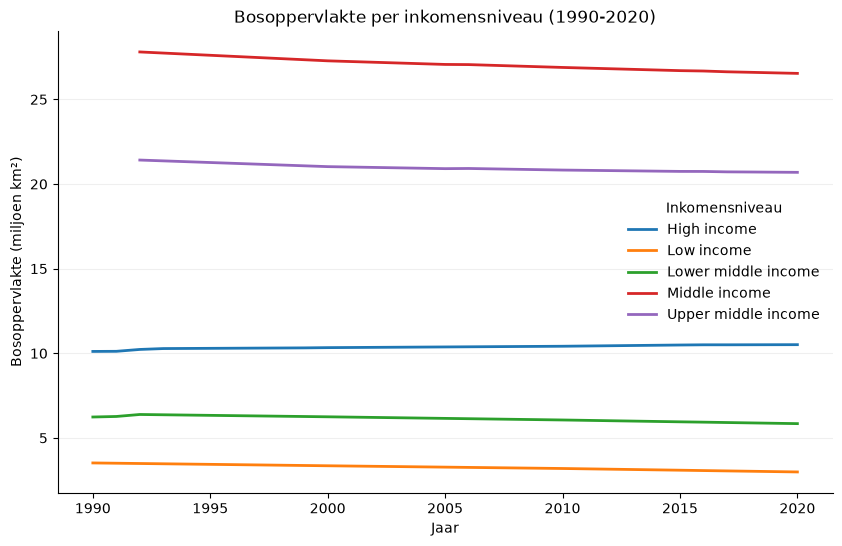

In [61]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=forest_b,
    x="year",
    y=forest_b["forest_area"] / 1000000,
    hue="area_name",
    linewidth=2
)

plt.title("Bosoppervlakte per inkomensniveau (1990-2020)")
plt.xlabel("Jaar")
plt.ylabel("Bosoppervlakte (miljoen km²)")
plt.legend(title="Inkomensniveau", frameon=False)

plt.grid(axis="y", alpha=0.2)
sns.despine()

plt.show()

### Onderbouwing grafiek B

**Grafiekkeuze:** Ik heb gekozen voor een lijngrafiek omdat
je hiermee de ontwikkeling over meerdere jaren goed kunt vergelijken.

**Clutter:** Ik heb onnodige randen verwijderd en de
rasterlijnen minder opvallend gemaakt. Ook wordt de
bosoppervlakte weergegeven in miljoenen km².

**Preattentive attributes:** Ik heb verschillende kleuren
gebruikt om de inkomensgroepen direct van elkaar te onderscheiden.

Voor Middle income en Upper middle income
ontbreken de gegevens van 1990 en 1991. Middle income
omvat daarnaast ook Lower middle income en Upper middle income.

# Opdracht D

In [62]:
groups = [
    "World",
    "Low income",
    "Lower middle income",
    "Middle income",
    "Upper middle income",
    "High income"
]

forest_d = forest[forest["area_name"].isin(groups)]
forest_d = forest_d[forest_d["year"] == 2020]
forest_d = forest_d.sort_values("forest_area")

display(forest_d)

,area_name,area_code,year,forest_area
8225,Low income,LIC,2020,2991863.4
8226,Lower middle income,LMC,2020,5845811.0
8213,High income,HIC,2020,10510106.5
8244,Upper middle income,UMC,2020,20689597.8
8230,Middle income,MIC,2020,26535408.8
8245,World,WLD,2020,40499687.7


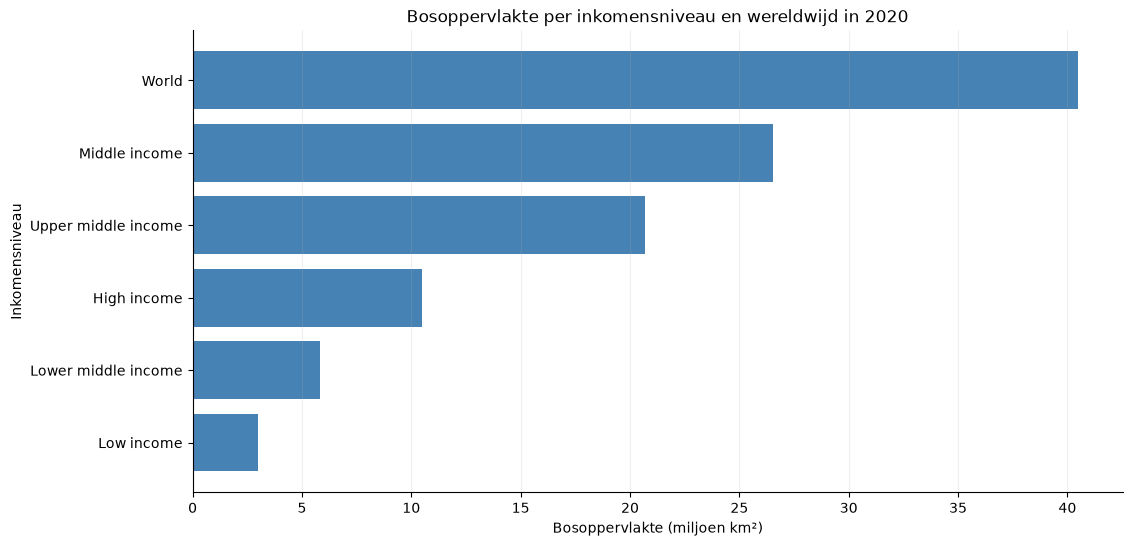

In [63]:
plt.figure(figsize=(12, 6))

plt.barh(
    forest_d["area_name"],
    forest_d["forest_area"] / 1000000,
    color="steelblue"
)

plt.title("Bosoppervlakte per inkomensniveau en wereldwijd in 2020")
plt.xlabel("Bosoppervlakte (miljoen km²)")
plt.ylabel("Inkomensniveau")

plt.grid(axis="x", alpha=0.2)
sns.despine()

plt.show()

### Onderbouwing grafiek D

**Grafiekkeuze:** Ik heb gekozen voor een horizontaal
staafdiagram omdat je hiermee de bosoppervlakte per
inkomensniveau in 2020 makkelijk kunt vergelijken.

**Clutter:** Ik heb overbodige randen verwijderd,
de rasterlijnen minder opvallend gemaakt en de
bosoppervlakte weergegeven in miljoenen km².

**Preattentive attributes:** Door de staven te sorteren
op grootte zijn de verschillen direct zichtbaar.
De lengte van de staven maakt vergelijken makkelijker.

World is het wereldtotaal. De categorie
Middle income omvat ook Lower middle income en
Upper middle income. De categorieën mogen daarom
niet bij elkaar worden opgeteld.

# Opdracht F

In [64]:
temperature = pd.read_csv("city_temperature_preprocessed.csv")

temperature_f = temperature[temperature["Country"] == "The Netherlands"]

display(temperature_f)

,Region,Country,City,Month,Day,Year,AvgTemperature
767088,Europe,The Netherlands,Amsterdam,1,1,1995,3.1
767089,Europe,The Netherlands,Amsterdam,1,2,1995,3.7
767090,Europe,The Netherlands,Amsterdam,1,3,1995,0.7
767091,Europe,The Netherlands,Amsterdam,1,4,1995,-1.6
767092,Europe,The Netherlands,Amsterdam,1,5,1995,-3.4
...,...,...,...,...,...,...,...
776185,Europe,The Netherlands,Amsterdam,12,27,2019,4.0
776186,Europe,The Netherlands,Amsterdam,12,28,2019,0.7
776187,Europe,The Netherlands,Amsterdam,12,29,2019,1.5
776188,Europe,The Netherlands,Amsterdam,12,30,2019,4.6


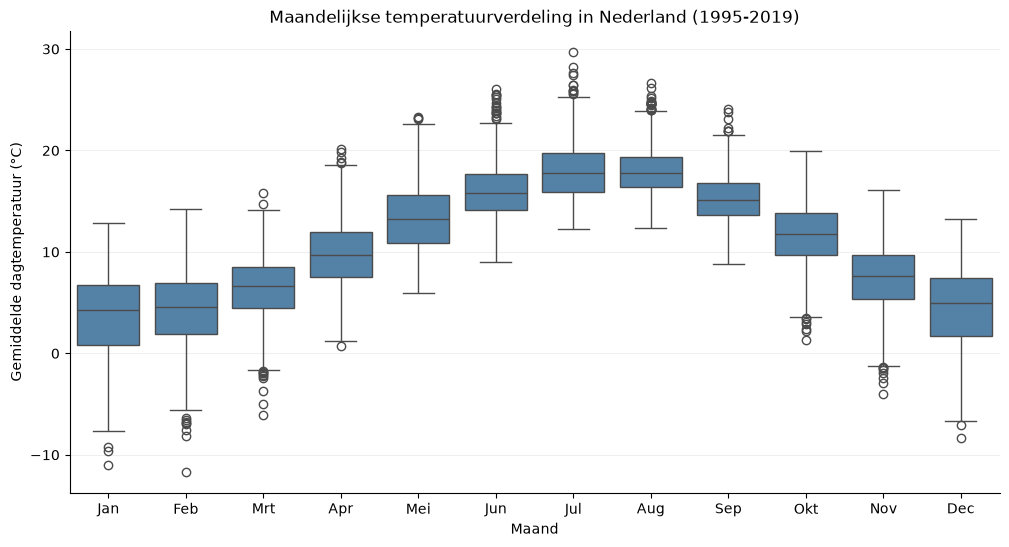

In [65]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=temperature_f,
    x="Month",
    y="AvgTemperature",
    color="steelblue"
)

plt.title("Maandelijkse temperatuurverdeling in Nederland (1995-2019)")
plt.xlabel("Maand")
plt.ylabel("Gemiddelde dagtemperatuur (°C)")

plt.xticks(
    range(12),
    ["Jan", "Feb", "Mrt", "Apr", "Mei", "Jun",
     "Jul", "Aug", "Sep", "Okt", "Nov", "Dec"]
)

plt.grid(axis="y", alpha=0.2)
sns.despine()

plt.show()

### Onderbouwing grafiek F

**Grafiekkeuze:** Ik heb gekozen voor boxplots omdat je
hiermee de mediaan, spreiding en uitschieters van de
temperaturen per maand goed kunt vergelijken.

**Clutter:** Ik heb overbodige randen verwijderd en
de rasterlijnen minder opvallend gemaakt.

**Preattentive attributes:** Door de verticale positie
en hoogte van de boxplots zijn verschillen in temperatuur
en spreiding direct zichtbaar.

De temperatuurgegevens van Nederland
zijn afkomstig uit Amsterdam en bevatten dagelijkse
gemiddelde temperaturen van 1995 tot en met 2019.